In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [3]:
prefix = '/mnt/staging/'

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

step_0_root = str(STEPS / "step_0") + "/"


data_root =  str(FIGURES / "figureS5") + "/"


In [4]:
def new_adjust_box_widths(axes, fac=0.9):
    """
    Adjust the widths of a seaborn-generated boxplot or boxenplot.
    
    Notes
    -----
    - thanks https://github.com/mwaskom/seaborn/issues/1076
    """
    from matplotlib.patches import PathPatch
    from matplotlib.collections import PatchCollection
    
    if isinstance(axes, list) is False:
        axes = [axes]

        
    x_offsets = [-0.8, 0.8]  # Adjust these values to control the separation between hue categories


    display_coordinates_1=[]
    display_coordinates_2=[]
        
        
    # iterating through Axes instances
    for ax in axes:

        # iterating through axes artists:
        for c in ax.get_children():
            # searching for PathPatches
            if isinstance(c, PathPatch) or isinstance(c, PatchCollection):
                if isinstance(c, PathPatch):
                    p = c.get_path()
                    x0_here = c.get_extents().x0
                else:
                    p = c.get_paths()[-1]
                    print('hii')
                    

        
                # getting current width of box:
#                 p = c.get_path()
                verts = p.vertices
                verts_sub = verts[:-1]
                xmin = np.min(verts_sub[:, 0])
                xmax = np.max(verts_sub[:, 0])
                xmid = 0.5 * (xmin + xmax)
                xhalf = 0.5 * (xmax - xmin)

                # setting new width of box
                xmin_new = xmid - fac * xhalf
                xmax_new = xmid + fac * xhalf
                verts_sub[verts_sub[:, 0] == xmin, 0] = xmin_new
                verts_sub[verts_sub[:, 0] == xmax, 0] = xmax_new

                # setting new width of median line
                for l in ax.lines:
                    try:
                        if np.all(l.get_xdata() == [xmin, xmax]):
                            l.set_xdata([xmin_new, xmax_new])
                    except:
                        # /tmp/ipykernel_138835/916607433.py:32: DeprecationWarning: elementwise comparison failed;
                            # this will raise an error in the future.
                                # if np.all(l.get_xdata() == [xmin, xmax]):
                        pass
    pass

In [5]:
dict_IDX_sorted = {}
dict_node_coords = {}
for mouse in ['cm219','cm229']:
    with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

        IDX_sorted = np.array(f_idx['IDX_sorted']).T
        IDX_sorted = IDX_sorted.astype(float)
        IDX_sorted[IDX_sorted==0]='nan'
        num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
        props = regionprops(IDX_sorted.astype(int))
        node_coords = [props[i].centroid for i in range(len(props))]
        node_coords = np.asarray(node_coords, dtype=np.float32)
        dict_IDX_sorted[mouse]=IDX_sorted
        dict_node_coords[mouse] = node_coords
        # mask = IDX_sorted >0
        # mask = mask.astype(float)
        # mask[mask==0]='nan'
    # plt.imshow(IDX_sorted)

In [6]:
dict_all = {'cm229':{},'cm219':{}}
for mouse in ['cm229','cm219']:
    for behavior_type in ['REST','RUN']:
        dict_all[mouse][behavior_type] = {}
        dict_everything_save = load_pickle(data_root+'csn-thy1-compare-trimmed-{}-'.format(behavior_type) + mouse)
        for key in dict_everything_save.keys():
            dict_all[mouse][behavior_type][key] = dict_everything_save[key]

In [8]:
choice_body_part_dict = dict_all['cm229']['REST']['choice_body_part_dict']
choice_dict = dict_all['cm229']['REST']['choice_dict']
dict_f = dict_all['cm229']['REST']['dict_f']['jrgeco']['RFP_S1']
trimmed_slinn = dict_all['cm229']['REST']['trimmed_dict_slinn']['jrgeco']['RFP_S1']




In [9]:
# avg_trimmed_slinn = trimmed_slinn.copy()
dict_trimmed_slinn = {}
# Average two mice's spectrogram
for behavior_type in ['REST','RUN']:
    dict_trimmed_slinn[behavior_type] = {}
    for fluorophore in ['jrgeco','gcamp']:
        dict_trimmed_slinn[behavior_type][fluorophore] = {}
        for bdp in ['RFP_S1','RFP_M1','RFP_M2']:
            dict_trimmed_slinn[behavior_type][fluorophore][bdp] = {}
            for mouse in ['cm229','cm219']:
                slinn_matrix = dict_all[mouse][behavior_type]['trimmed_dict_slinn'][fluorophore][bdp]
                dict_trimmed_slinn[behavior_type][fluorophore][bdp][mouse] = slinn_matrix


In [10]:
dict_avg_trimmed_slinn = {}
for behavior_type in ['REST','RUN']:
    dict_avg_trimmed_slinn[behavior_type] = {}
    for fluorophore in ['jrgeco','gcamp']:
        dict_avg_trimmed_slinn[behavior_type][fluorophore]={}
        for bdp in ['RFP_S1','RFP_M1','RFP_M2']:
            dict_avg_trimmed_slinn[behavior_type][fluorophore][bdp] = np.concatenate((
                dict_trimmed_slinn[behavior_type][fluorophore][bdp][
                'cm219'],dict_trimmed_slinn[behavior_type][fluorophore][bdp][
                'cm229']),axis=1)
            


In [11]:
for behavior_type in ['REST','RUN']:
    print(behavior_type,': # of bouts cm219:',dict_trimmed_slinn[behavior_type][fluorophore][bdp]['cm219'].shape[1],
          ' cm229:',dict_trimmed_slinn[behavior_type][fluorophore][bdp]['cm229'].shape[1])

REST : # of bouts cm219: 75  cm229: 102
RUN : # of bouts cm219: 67  cm229: 39


In [13]:
spectrogram_cmap = load_pickle(figure_config_root+'spectrogram_cmap')



In [14]:
dict_bdp_short = {'RFP_M1':"M1(RFP)",
                 'RFP_M2':"M2(RFP)",
                 'RFP_S1':"S1(RFP)"}

## Suppl Fig 6e + 6h - averaged spectrograms

Thy1 (i) and CSN (ii) activity at the three forepaw ROIs, resting (6e, n=177 epochs) and locomotion (6h, n=106).


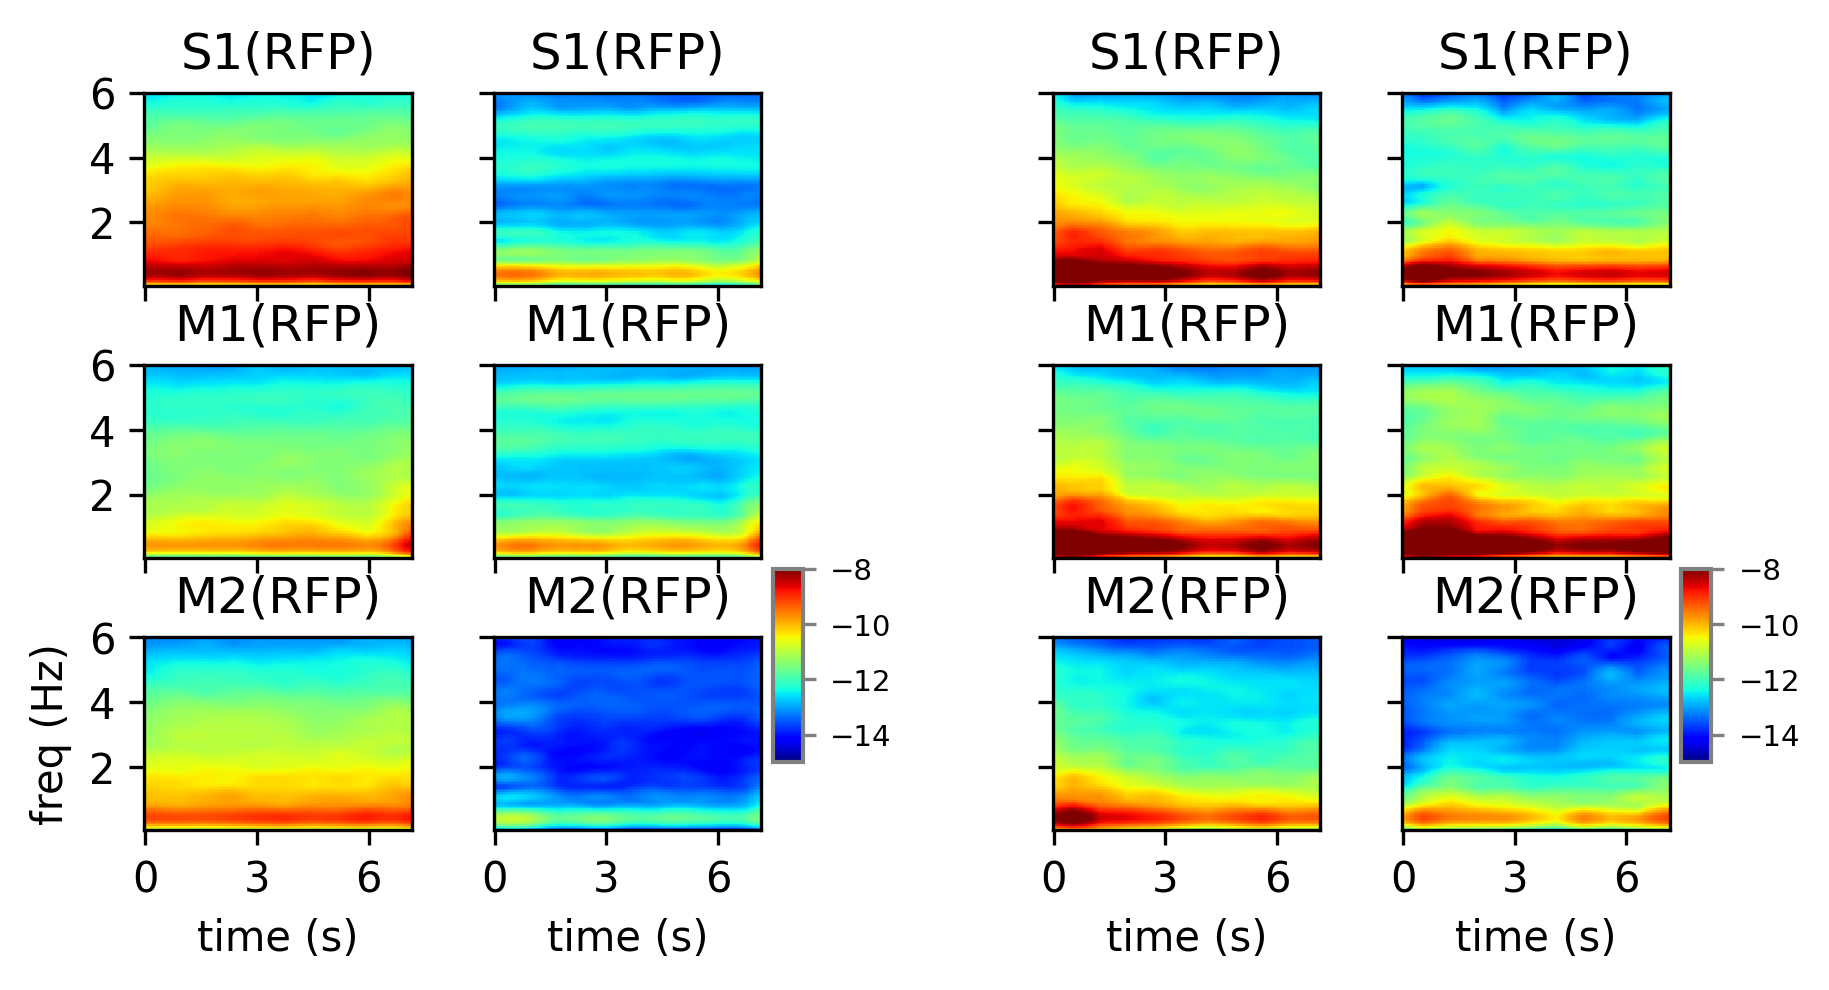

In [14]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)

plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset = 20; x_width = 4; y_width = 3

# 
x_start = x_offset 
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width

x_start = x_stop+1
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width
    
ax990 = fig.add_subplot(gs[y_start-2-y_width:y_start-2,x_stop:x_stop+2])

x_start = x_stop+4
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(6,9):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width

x_start = x_stop+1
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(9,12):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width
    
ax991 = fig.add_subplot(gs[y_start-2-y_width:y_start-2,x_stop:x_stop+2])

#############################################
x=np.arange(120)
my_xticks = np.divide(x,15)

for i_behavior_type, behavior_type in enumerate(['REST','RUN']):
    for i_fluorophore, fluorophore in enumerate(['jrgeco','gcamp']):
        for i_bdp, bdp in enumerate(['RFP_S1', 'RFP_M1', 'RFP_M2']):
    
            ax_num = 6*i_behavior_type + 3*i_fluorophore + i_bdp
            f=dict_f;Slinn=dict_avg_trimmed_slinn[behavior_type][fluorophore][bdp]
            exec("sbp0 = ax{}.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),rasterized=True,vmin=-15,vmax=-8,cmap='jet')".format(ax_num))
            exec("ax{}.set_ylim([0.05,6])".format(ax_num))
            exec("ax{}.set_yticks([2,4,6])".format(ax_num))
            exec("ax{}.set_xticks(np.array(x[::50],dtype='int'),np.array(my_xticks[::50],dtype='int'));".format(ax_num))

            if ax_num > 2:
                exec("ax{}.set_yticklabels([])".format(ax_num))
            if ax_num==2:
                exec("ax{}.set_ylabel('freq (Hz)')".format(ax_num))
            if i_bdp != 2: 
                exec("ax{}.set_xticklabels([])".format(ax_num))
            else:
                exec("ax{}.set_xlabel('time (s)')".format(ax_num))
            
            exec("ax{}.set_title(dict_bdp_short[bdp])".format(ax_num))
            
for i_colorbar in [0,1]:           
    exec("cb = fig.colorbar(sbp0, cax=ax99{},fraction=0.5,orientation='vertical');".format(i_colorbar))
    cb.ax.tick_params(labelsize=7,length=3,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(1)
    tick_locator = ticker.MaxNLocator(nbins=4)
    cb.locator = tick_locator
    cb.update_ticks()
    exec("ax99{}.set_aspect(0.92);ax99{}.set_anchor('W')".format(i_colorbar,i_colorbar))
    
    
# plt.savefig('figS6-spectrogram-csn-thy1-compare.svg',format='svg',dpi=300)

# compare between S1, M1 and M2

## Suppl Fig 6c + 6f - log spectral power across S1, M1, M2

CSN (i) and Thy1 (ii), resting (6c, n=177) and locomotion (6f, n=106). Gray lines are individual epochs, black is the group mean. Two-sided Wilcoxon signed-rank tests on all three pairwise region comparisons.


Wilcoxon signed-rank tests (spectral power, 0.05–6 Hz)

REST — gcamp (n=177 bouts)
  S1 vs M1: W=761.0, p=1.94e-25, mean diff=-0.4197
  S1 vs M2: W=116.0, p=6.03e-30, mean diff=1.1462
  M1 vs M2: W=43.0, p=1.76e-30, mean diff=1.5659

REST — jrgeco (n=177 bouts)
  S1 vs M1: W=5.0, p=9.25e-31, mean diff=1.1428
  S1 vs M2: W=0.0, p=8.49e-31, mean diff=0.9659
  M1 vs M2: W=5295.0, p=1.56e-04, mean diff=-0.1769

RUN — gcamp (n=106 bouts)
  S1 vs M1: W=78.0, p=3.58e-18, mean diff=-0.7553
  S1 vs M2: W=0.0, p=3.99e-19, mean diff=1.2179
  M1 vs M2: W=1.0, p=4.11e-19, mean diff=1.9732

RUN — jrgeco (n=106 bouts)
  S1 vs M1: W=555.0, p=6.58e-13, mean diff=0.2181
  S1 vs M2: W=0.0, p=3.99e-19, mean diff=1.0542
  M1 vs M2: W=3.0, p=4.35e-19, mean diff=0.8361


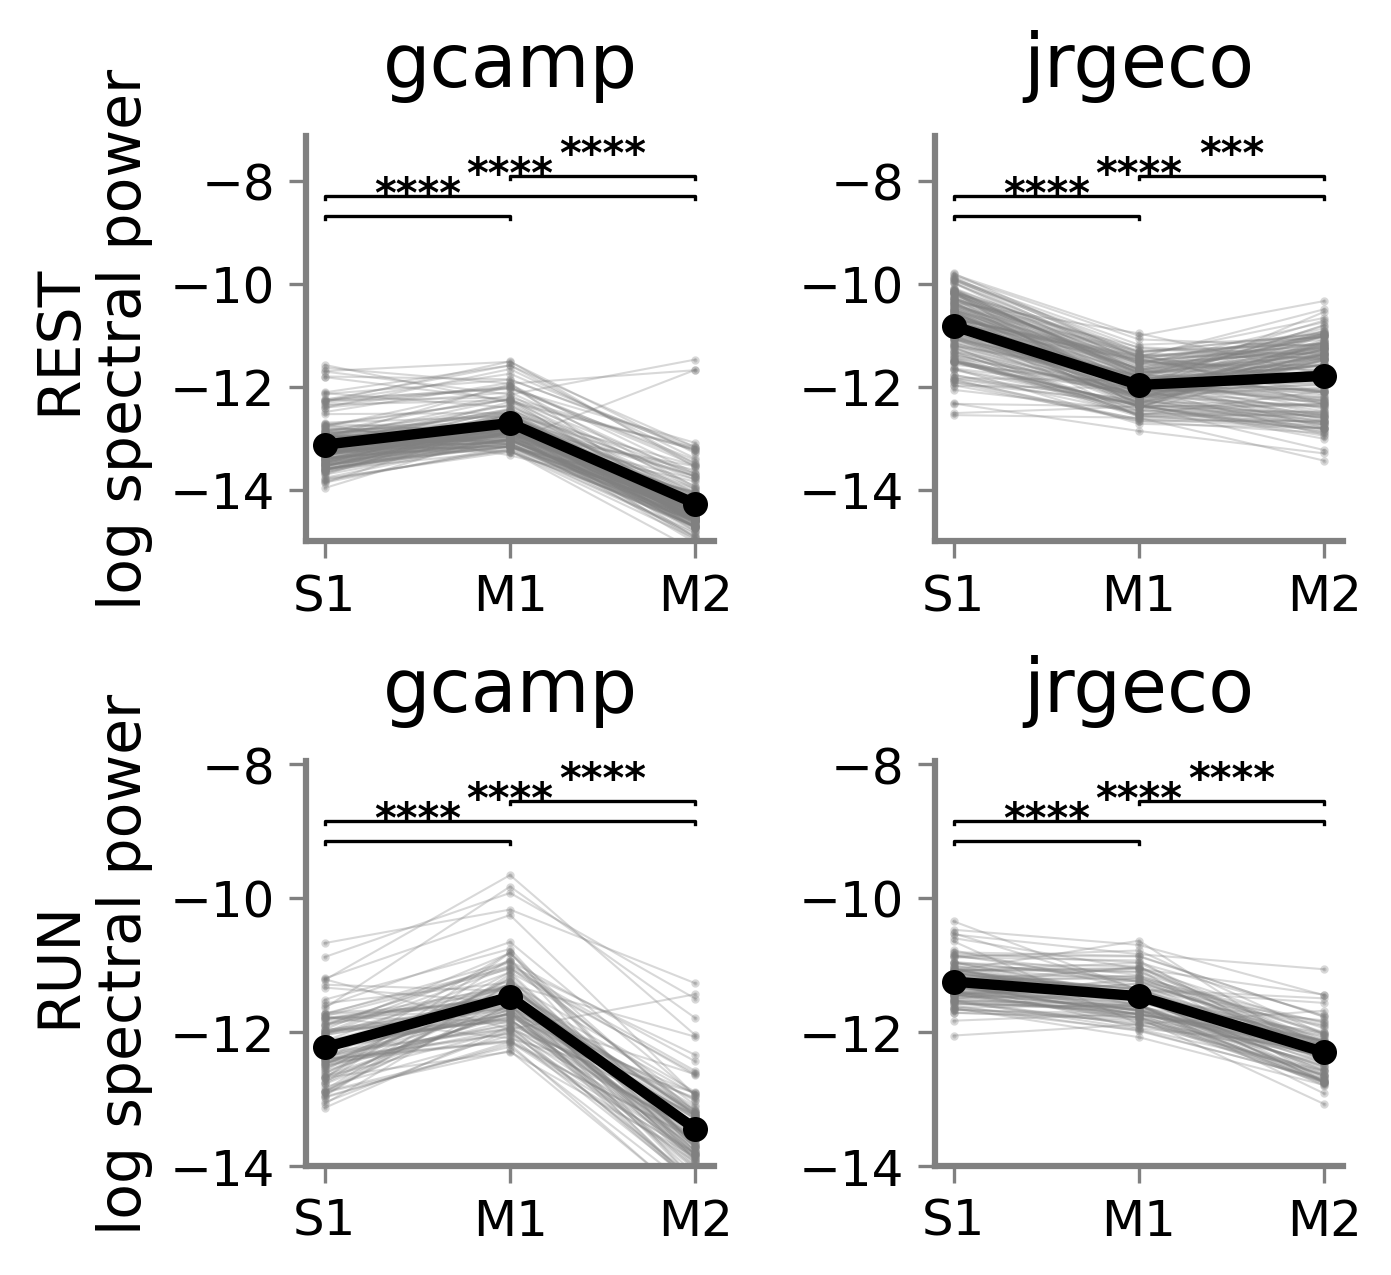

In [27]:
from scipy import stats
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib import ticker

regions = ['RFP_S1', 'RFP_M1', 'RFP_M2']
region_labels = ['S1', 'M1', 'M2']

f = dict_all['cm229']['REST']['dict_f']['jrgeco']['RFP_S1']
freq_mask = (f >= 0.05) & (f <= 6)

def compute_band_power(slinn_3d, f, freq_mask):
    n_bouts = slinn_3d.shape[1]
    bout_power = np.zeros(n_bouts)
    for b in range(n_bouts):
        spec = slinn_3d[:, b, :]
        bout_power[b] = np.nanmean(np.log(spec[freq_mask, :]))
    return bout_power

power_data = {}
for behavior_type in ['REST', 'RUN']:
    power_data[behavior_type] = {}
    for fluorophore in ['gcamp', 'jrgeco']:
        power_data[behavior_type][fluorophore] = {}
        for bdp in regions:
            slinn_combined = np.concatenate([
                dict_all['cm219'][behavior_type]['trimmed_dict_slinn'][fluorophore][bdp],
                dict_all['cm229'][behavior_type]['trimmed_dict_slinn'][fluorophore][bdp]
            ], axis=1)
            power_data[behavior_type][fluorophore][bdp] = compute_band_power(slinn_combined, f, freq_mask)

# ══════════════════════════════════════════════════════════════════
# FIGURE SETUP — matching your GridSpec style
# ══════════════════════════════════════════════════════════════════
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

fig = plt.figure(figsize=(30, 30), dpi=300)
gs = GridSpec(100, 100)

# Layout: 2 rows x 2 cols of spectral power panels
# Row 0 = REST, Row 1 = RUN; Col 0 = gcamp, Col 1 = jrgeco
panel_size_x = 6
panel_size_y = 6
x_gap = 3
y_gap = 3
x_base = 10
y_base = 20

layout = [
    (0, 0, 'REST', 'gcamp'),
    (0, 1, 'REST', 'jrgeco'),
    (1, 0, 'RUN', 'gcamp'),
    (1, 1, 'RUN', 'jrgeco'),
]

pairs = list(combinations(range(3), 2))

ylims = {
    'REST': [-15, -8.5],
    'RUN': [-14, -9],
}

print("=" * 80)
print("Wilcoxon signed-rank tests (spectral power, 0.05–6 Hz)")
print("=" * 80)

for row, col, behavior_type, fluorophore in layout:
    y_start = y_base + row * (panel_size_y + y_gap)
    x_start = x_base + col * (panel_size_x + x_gap)
    ax = fig.add_subplot(gs[y_start:y_start + panel_size_y,
                            x_start:x_start + panel_size_x])

    vals = [power_data[behavior_type][fluorophore][bdp] for bdp in regions]
    n_bouts = len(vals[0])

    # Individual bout lines
    for b in range(n_bouts):
        ax.plot([0, 1, 2], [vals[0][b], vals[1][b], vals[2][b]],
                color='gray', alpha=0.3, linewidth=0.5, marker='.', markersize=2)

    # Mean line
    means = [np.mean(v) for v in vals]
    ax.plot([0, 1, 2], means, color='black', linewidth=2.5, marker='o', markersize=5)

    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(region_labels, fontsize=14)
    ax.set_title(fluorophore, fontsize=18, pad=12)

    if col == 0:
        ax.set_ylabel(f'{behavior_type}\nlog spectral power', fontsize=14)

    # Spine styling to match your correlation map panels
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_edgecolor('gray')
        ax.spines[spine].set_linewidth(1.5)

    ax.tick_params(labelsize=12, length=4, color='gray')

    # Fixed y-limits
    ylo, yhi = ylims[behavior_type]
    y_range = yhi - ylo
    y_step = y_range * 0.06

    # Stats + brackets
    print(f"\n{behavior_type} — {fluorophore} (n={n_bouts} bouts)")
    for k, (i, j) in enumerate(pairs):
        stat, p_val = stats.wilcoxon(vals[i], vals[j])

        if p_val < 0.0001:    sig = '****'
        elif p_val < 0.001:   sig = '***'
        elif p_val < 0.01:    sig = '**'
        elif p_val < 0.05:    sig = '*'
        else:                 sig = 'n.s.'

        print(f"  {region_labels[i]} vs {region_labels[j]}: "
              f"W={stat:.1f}, p={p_val:.2e}, "
              f"mean diff={np.mean(vals[i] - vals[j]):.4f}")

        y_bar = yhi - y_step * 0.5 + y_step * k
        ax.plot([i, i, j, j],
                [y_bar - y_step * 0.15, y_bar, y_bar, y_bar - y_step * 0.15],
                color='black', linewidth=0.8)
        ax.text((i + j) / 2, y_bar, sig, ha='center', va='bottom',
                fontsize=10, fontweight='bold')

    ax.set_ylim([ylo, yhi + y_step * (len(pairs) + 0.5)])

plt.savefig('figS6-spectral-power-stats.svg', format='svg', dpi=300)
plt.show()

In [16]:
for mouse in ['cm229', 'cm219']:
    for behavior_type in ['REST', 'RUN']:
        cd = dict_all[mouse][behavior_type]['choice_dict']
        print(f"{mouse} {behavior_type} choice_dict: {cd}")
        print(f"  norm_M_gcamp shape: {dict_all[mouse][behavior_type]['norm_M_gcamp'].shape}")
        print(f"  norm_M_jrgeco shape: {dict_all[mouse][behavior_type]['norm_M_jrgeco'].shape}")

cm229 REST choice_dict: {0: 413, 1: 322, 2: 338}
  norm_M_gcamp shape: (500, 120, 102)
  norm_M_jrgeco shape: (500, 120, 102)
cm229 RUN choice_dict: {0: 413, 1: 322, 2: []}
  norm_M_gcamp shape: (500, 120, 39)
  norm_M_jrgeco shape: (500, 120, 39)
cm219 REST choice_dict: {0: 403, 1: 315, 2: 280}
  norm_M_gcamp shape: (500, 120, 75)
  norm_M_jrgeco shape: (500, 120, 75)
cm219 RUN choice_dict: {0: 403, 1: 315, 2: 280}
  norm_M_gcamp shape: (500, 120, 67)
  norm_M_jrgeco shape: (500, 120, 67)


In [17]:
# Fix cm229 RUN M2 index to match REST
dict_all['cm229']['RUN']['choice_dict'][2] = dict_all['cm229']['REST']['choice_dict'][2]

# make brain maps

In [166]:
mouse = 'cm229'
dict_avg_amplitude={}
for behavior_type in ['REST','RUN']:
    dict_avg_amplitude[behavior_type] = {}
    for fluorophore in ['jrgeco','gcamp']:
        dict_avg_amplitude[behavior_type][fluorophore] = np.mean(np.mean(
            dict_all[mouse][behavior_type]['norm_M_'+fluorophore],-1),-1)

dict_avg_std= {}
for behavior_type in ['REST','RUN']:
    dict_avg_std[behavior_type] = {}
    for fluorophore in ['jrgeco','gcamp']:
        dict_avg_std[behavior_type][fluorophore] = np.mean(np.mean(
            dict_all[mouse][behavior_type]['norm_M_'+fluorophore+'_std'],-1),-1)

In [167]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
fire_cmap = load_pickle(figure_config_root+'fire_cmap')
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
# cm229 ONLY
new_choice_ind={'cm229':{},'cm219':{}}
new_choice_ind['cm229']['M2']=338 # CM229
new_choice_ind['cm229']['S1']=412 # CM229
new_choice_ind['cm229']['M1']=322 # CM229

new_choice_ind['cm219']['M2']=280 # CM219
new_choice_ind['cm219']['S1']=403 # CM219
new_choice_ind['cm219']['M1']=315 # CM219

## Suppl Fig 6d + 6g - amplitude and temporal-variance maps

Averaged amplitude and rolling variance for Thy1 (i) and CSN (ii), from a single mouse: resting (6d, n=102 epochs) and locomotion (6g, n=39).


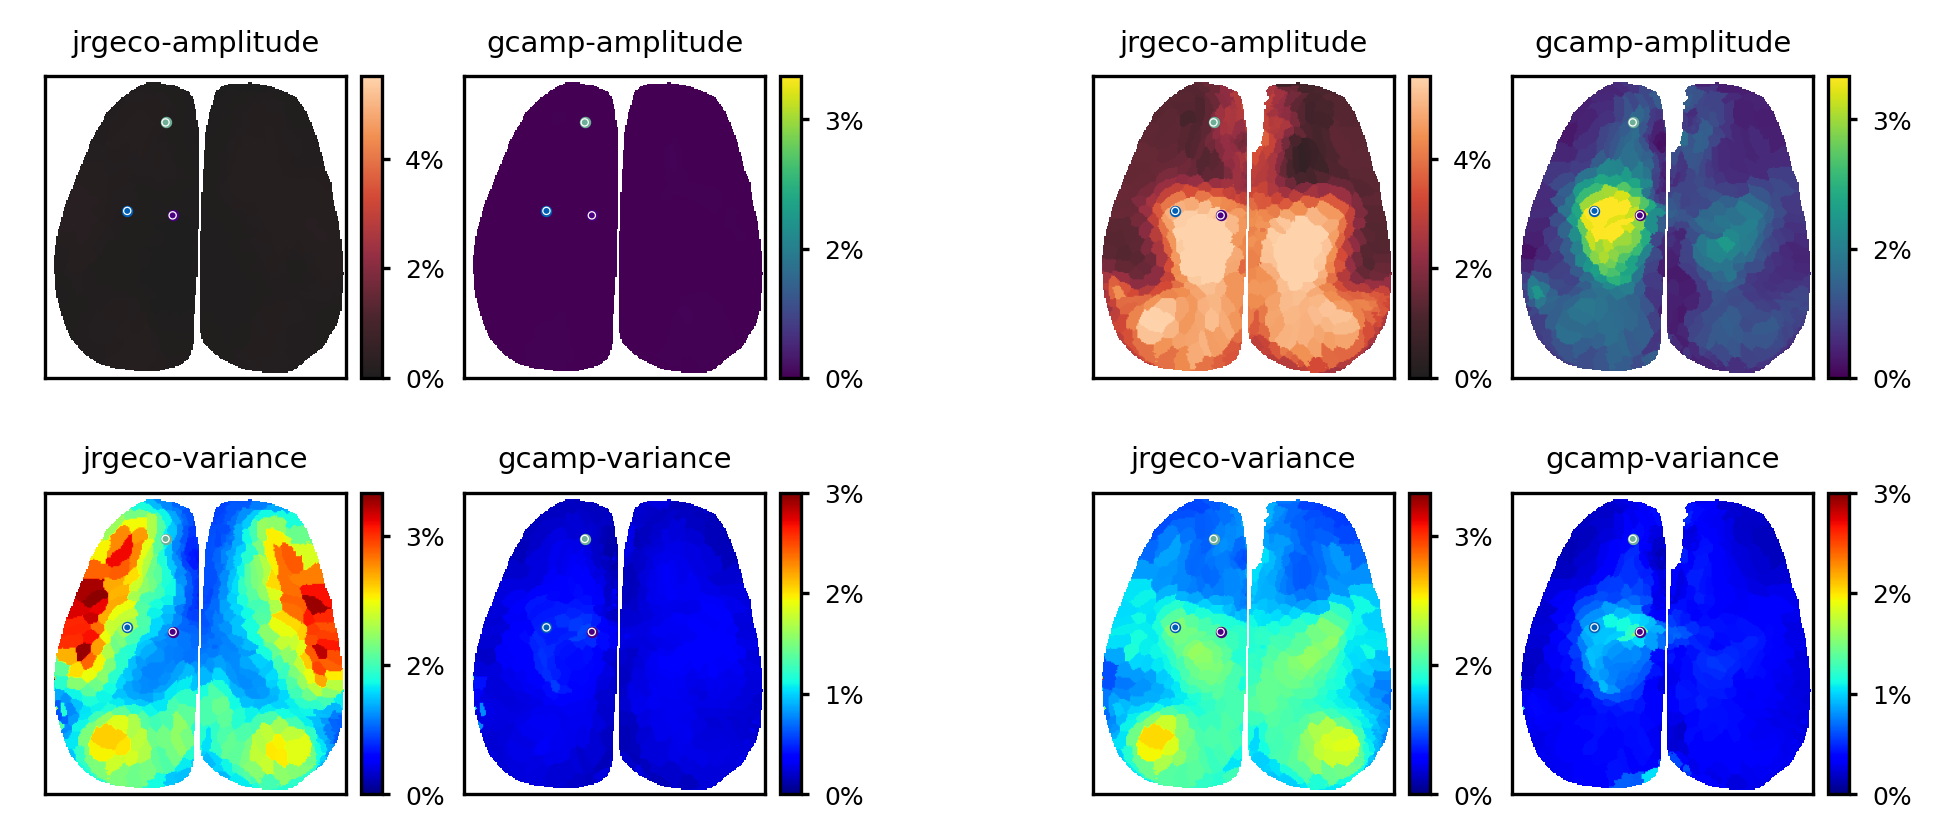

In [168]:
plt.style.use('default')
gs = GridSpec(100,100)

plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset = 20; x_width = 5; y_width = 5

# 
x_start = x_offset 
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(0,2):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width

x_start = x_stop+1
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(2,4):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width
    
# ax990 = fig.add_subplot(gs[y_start-1-y_width:y_start-1,x_stop:x_stop+2])
x_start = x_stop+4
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(4,6):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width

x_start = x_stop+1
x_stop = x_start+x_width
y_start = y_offset 
y_stop = y_start+y_width
for i_ax in range(6,8):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 1
    y_stop = y_start + y_width
    

for i_behavior_type, behavior_type in enumerate(['REST','RUN']):
    for i_fluorophore, fluorophore in enumerate(['jrgeco','gcamp']):
        avg_brain_map = dict_avg_amplitude[behavior_type][fluorophore] 
        brain_map_to_show = show_map(avg_brain_map,caxis=[-0,0.0],if_return_map=True, cmap='icefire',
         IDX_sorted=dict_IDX_sorted['cm229'])
        ax_num = 4*i_behavior_type + 2*i_fluorophore + 0 
        if fluorophore=='jrgeco':
            exec("sbp{} = ax{}.imshow(np.multiply(brain_map_to_show,mask_midline),vmin=-0.0,vmax=0.055,cmap=fire_cmap)".format(ax_num,ax_num))
        elif fluorophore=='gcamp':
            exec("sbp{} = ax{}.imshow(np.multiply(brain_map_to_show,mask_midline),vmin=-0.0,vmax=0.035,cmap='viridis')".format(ax_num,ax_num))
        exec("ax{}.set_title(fluorophore+'-'+'amplitude',fontsize=7)".format(ax_num))
        
        avg_brain_map = dict_avg_std[behavior_type][fluorophore] 
        brain_map_to_show = show_map(avg_brain_map,caxis=[-0.0,0.0],if_return_map=True, cmap='jet',
         IDX_sorted=dict_IDX_sorted['cm229'])
        ax_num = 4*i_behavior_type + 2*i_fluorophore + 1
        if fluorophore=='jrgeco':
            exec("sbp{} = ax{}.imshow(np.multiply(brain_map_to_show,mask_midline),vmin=-0.0,vmax=0.035,cmap='jet')".format(ax_num,ax_num))
        elif fluorophore=='gcamp':        
            exec("sbp{} = ax{}.imshow(np.multiply(brain_map_to_show,mask_midline),vmin=-0.0,vmax=0.03,cmap='jet')".format(ax_num,ax_num))
        exec("ax{}.set_title(fluorophore+'-'+'variance',fontsize=7)".format(ax_num))
        
for i_ax in range(8):
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    for i_key,key in enumerate(new_choice_ind['cm229']):
        ind = new_choice_ind['cm229'][key]
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=3,color=palatte_dict['RFP_'+key])".format(i_ax))
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=3,facecolors='none',linewidths=0.3, edgecolors='white')".format(i_ax))

        
        
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from matplotlib import ticker
for i_ax in range(8):
    exec("div = make_axes_locatable(ax{})".format(i_ax))
    cax = div.append_axes('right', '7%', '5%')
    exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical',format=FuncFormatter(fmt))".format(i_ax))
    cb.ax.tick_params(labelsize=6,length=2,color='black')
    cb.ax.yaxis.tick_right()
    cb.outline.set_edgecolor('black')
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    # cb.outline.set_linewidth(1)

plt.savefig('figS6-brain-maps-csn-thy1-compare.svg',format='svg',dpi=300)